In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

In [9]:
file_path = "../data/raw/Inventory_SupplyChain_Dataset.csv"
df = pd.read_csv(file_path)

In [10]:
df.shape

(1200, 15)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       1200 non-null   object 
 1   Region                     1200 non-null   object 
 2   Category                   1200 non-null   object 
 3   Supplier                   1200 non-null   object 
 4   Warehouse                  1200 non-null   object 
 5   Order Status               1200 non-null   object 
 6   Units Sold                 1200 non-null   int64  
 7   Inventory Level            1200 non-null   int64  
 8   Transportation Cost        1200 non-null   float64
 9   Order Accuracy             1200 non-null   bool   
 10  Lead Time (Days)           1200 non-null   int64  
 11  Backorder                  1200 non-null   bool   
 12  Cost of Goods Sold (COGS)  1200 non-null   float64
 13  Average Inventory          1200 non-null   float

In [13]:
df.duplicated().sum()

0

In [14]:
df.isnull().sum()

Date                         0
Region                       0
Category                     0
Supplier                     0
Warehouse                    0
Order Status                 0
Units Sold                   0
Inventory Level              0
Transportation Cost          0
Order Accuracy               0
Lead Time (Days)             0
Backorder                    0
Cost of Goods Sold (COGS)    0
Average Inventory            0
Warehouse Capacity           0
dtype: int64

In [15]:
df.head()

,Date,Region,Category,Supplier,Warehouse,Order Status,Units Sold,Inventory Level,Transportation Cost,Order Accuracy,Lead Time (Days),Backorder,Cost of Goods Sold (COGS),Average Inventory,Warehouse Capacity
0,14-01-2020,North,Accessories,Supplier A,Warehouse 1,Fulfilled,302,2124,1103.838324,True,9,False,37820.05240,2048.0,5037
1,15-11-2020,East,Furniture,Supplier D,Warehouse 2,Fulfilled,741,1972,13163.007660,True,11,False,54396.17369,1213.0,9216
2,16-04-2020,East,Furniture,Supplier C,Warehouse 2,Fulfilled,940,454,9872.294126,True,17,False,24217.45462,1160.5,7699
3,17-04-2020,South,Accessories,Supplier D,Warehouse 2,Canceled,589,1867,4547.589932,True,3,False,38919.08005,3364.5,9271
4,18-04-2020,North,Accessories,Supplier C,Warehouse 2,Fulfilled,964,4862,11994.042310,True,21,False,59204.50683,3063.0,5828


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       1200 non-null   object 
 1   Region                     1200 non-null   object 
 2   Category                   1200 non-null   object 
 3   Supplier                   1200 non-null   object 
 4   Warehouse                  1200 non-null   object 
 5   Order Status               1200 non-null   object 
 6   Units Sold                 1200 non-null   int64  
 7   Inventory Level            1200 non-null   int64  
 8   Transportation Cost        1200 non-null   float64
 9   Order Accuracy             1200 non-null   bool   
 10  Lead Time (Days)           1200 non-null   int64  
 11  Backorder                  1200 non-null   bool   
 12  Cost of Goods Sold (COGS)  1200 non-null   float64
 13  Average Inventory          1200 non-null   float

In [18]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].unique())


Date
['14-01-2020' '15-11-2020' '16-04-2020' ... '03-01-2023' '02-01-2023'
 '01-01-2023']

Region
['North' 'East' 'South' 'West']

Category
['Accessories' 'Furniture' 'Electronics' 'Clothing']

Supplier
['Supplier A' 'Supplier D' 'Supplier C' 'Supplier B']

Warehouse
['Warehouse 1' 'Warehouse 2' 'Warehouse 3']

Order Status
['Fulfilled' 'Canceled' 'Pending']


In [19]:
df.nunique()

Date                         1200
Region                          4
Category                        4
Supplier                        4
Warehouse                       3
Order Status                    3
Units Sold                    683
Inventory Level              1069
Transportation Cost          1200
Order Accuracy                  2
Lead Time (Days)               29
Backorder                       2
Cost of Goods Sold (COGS)    1200
Average Inventory            1103
Warehouse Capacity           1044
dtype: int64

In [20]:
df['Region'].unique()

array(['North', 'East', 'South', 'West'], dtype=object)

In [21]:
df['Category'].unique()

array(['Accessories', 'Furniture', 'Electronics', 'Clothing'],
      dtype=object)

In [22]:
df['Supplier'].unique()

array(['Supplier A', 'Supplier D', 'Supplier C', 'Supplier B'],
      dtype=object)

In [23]:
df['Warehouse'].unique()

array(['Warehouse 1', 'Warehouse 2', 'Warehouse 3'], dtype=object)

In [24]:
df['Order Status'].unique()

array(['Fulfilled', 'Canceled', 'Pending'], dtype=object)

In [25]:
df.describe()

,Units Sold,Inventory Level,Transportation Cost,Lead Time (Days),Cost of Goods Sold (COGS),Average Inventory,Warehouse Capacity
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,533.892500,2530.473333,7723.518494,15.739167,59370.480017,2529.588333,7425.831667
std,275.469524,1416.945265,4202.727652,8.442187,44542.532052,1000.512796,1460.827133
min,50.000000,101.000000,509.098991,1.000000,1415.613541,235.000000,5002.000000
25%,298.000000,1261.750000,4145.882050,8.000000,22982.367025,1843.000000,6116.500000
50%,529.000000,2623.500000,7759.647979,16.000000,47773.376750,2496.500000,7427.000000
75%,777.000000,3726.250000,11154.018832,23.000000,88006.544317,3240.125000,8662.250000
max,999.000000,4999.000000,14997.814050,29.000000,190841.495400,4863.500000,9995.000000


In [28]:
df['Date'].dtype

dtype('O')

In [29]:
dates = pd.to_datetime(df["Date"], errors="coerce")

print("Earliest date:", dates.min())
print("Latest date:", dates.max())
print("Invalid dates:", dates.isna().sum())

Earliest date: 2020-01-14 00:00:00
Latest date: 2024-12-31 00:00:00
Invalid dates: 0


C:\Users\IENOVO\AppData\Local\Temp\ipykernel_4588\2767809039.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  dates = pd.to_datetime(df["Date"], errors="coerce")


In [42]:
df['Date'] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

In [44]:
df['Date'].dtype

dtype('<M8[ns]')

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 16 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       1200 non-null   datetime64[ns]
 1   Region                     1200 non-null   object        
 2   Category                   1200 non-null   object        
 3   Supplier                   1200 non-null   object        
 4   Warehouse                  1200 non-null   object        
 5   Order Status               1200 non-null   object        
 6   Units Sold                 1200 non-null   int64         
 7   Inventory Level            1200 non-null   int64         
 8   Transportation Cost        1200 non-null   float64       
 9   Order Accuracy             1200 non-null   bool          
 10  Lead Time (Days)           1200 non-null   int64         
 11  Backorder                  1200 non-null   bool          
 12  Cost o

In [48]:
df.drop(columns=['Dates'], inplace=True)

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 15 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       1200 non-null   datetime64[ns]
 1   Region                     1200 non-null   object        
 2   Category                   1200 non-null   object        
 3   Supplier                   1200 non-null   object        
 4   Warehouse                  1200 non-null   object        
 5   Order Status               1200 non-null   object        
 6   Units Sold                 1200 non-null   int64         
 7   Inventory Level            1200 non-null   int64         
 8   Transportation Cost        1200 non-null   float64       
 9   Order Accuracy             1200 non-null   bool          
 10  Lead Time (Days)           1200 non-null   int64         
 11  Backorder                  1200 non-null   bool          
 12  Cost o

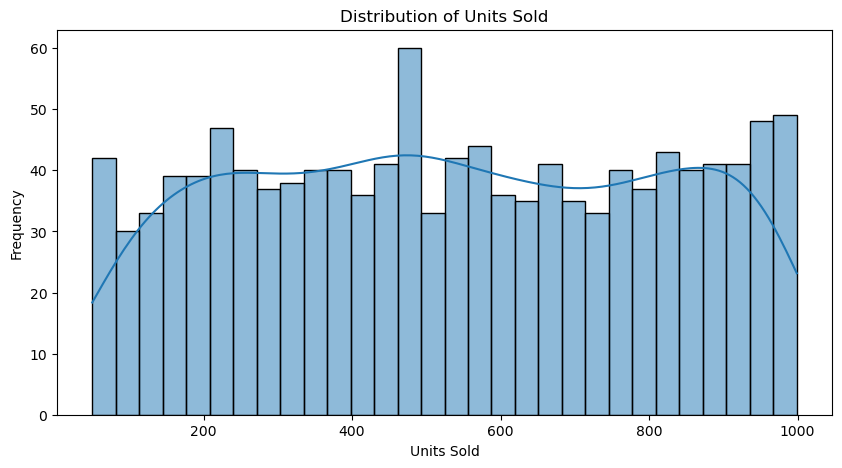

In [50]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Units Sold",
    bins=30,
    kde=True
)

plt.title("Distribution of Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")

plt.show()

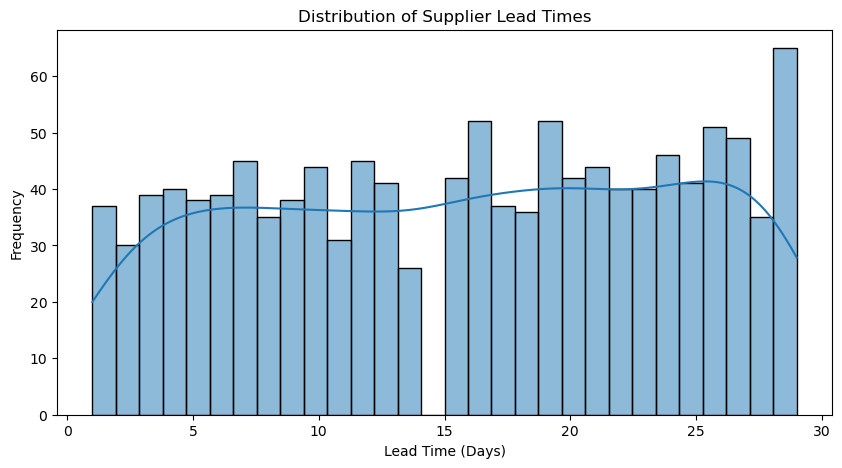

In [51]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Lead Time (Days)",
    bins=30,
    kde=True
)

plt.title("Distribution of Supplier Lead Times")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Frequency")

plt.show()

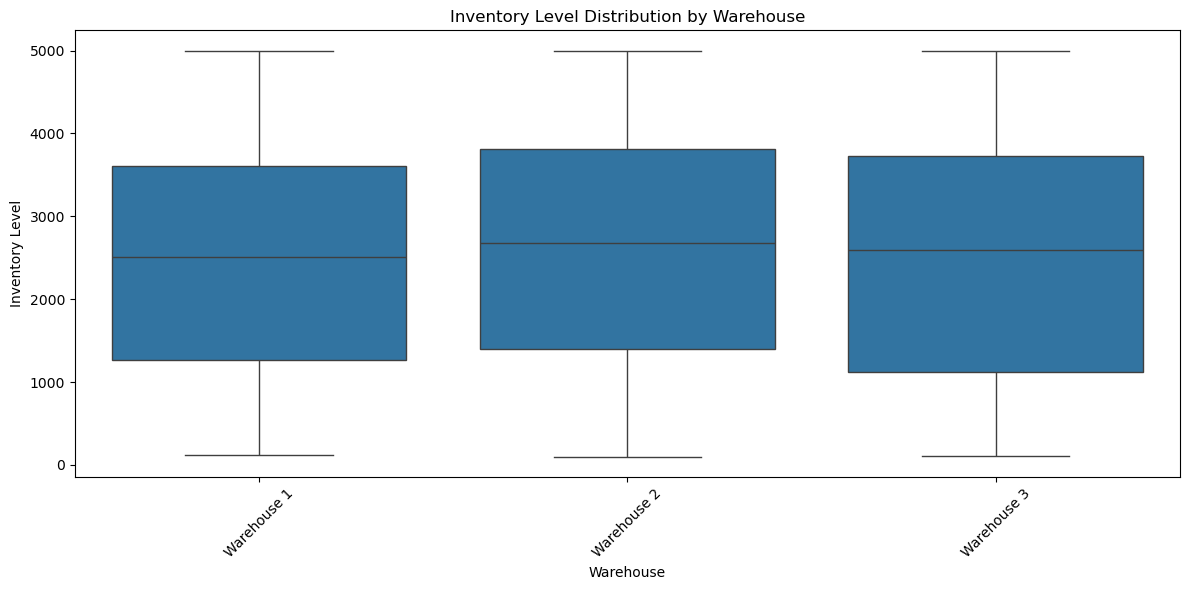

In [52]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="Warehouse",
    y="Inventory Level"
)

plt.title("Inventory Level Distribution by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Inventory Level")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [57]:
df["Backorder"].value_counts(dropna=False)

Backorder
False    1084
True      116
Name: count, dtype: int64

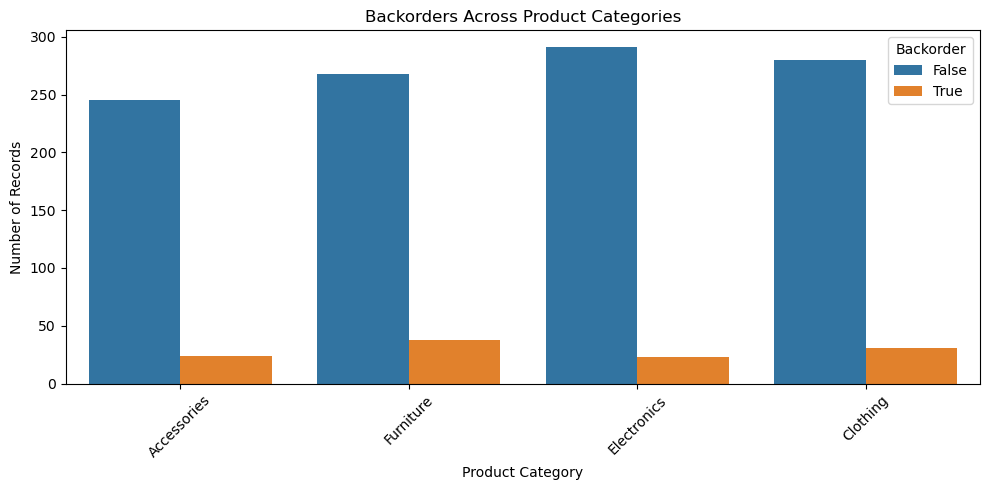

In [56]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Category",
    hue="Backorder"
)

plt.title("Backorders Across Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [58]:
supplier_lead_time = (
    df.groupby("Supplier")["Lead Time (Days)"]
    .mean()
    .sort_values(ascending=False)
)

supplier_lead_time

Supplier
Supplier B    16.170968
Supplier D    16.000000
Supplier C    15.538182
Supplier A    15.233974
Name: Lead Time (Days), dtype: float64

In [59]:
transportation_by_region = (
    df.groupby("Region")["Transportation Cost"]
    .agg(["sum", "mean", "count"])
    .sort_values(by="sum", ascending=False)
)

transportation_by_region

,sum,mean,count
Region,,,
North,2.498743e+06,7882.469782,317
West,2.437561e+06,7689.466044,317
East,2.265510e+06,7977.147956,284
South,2.066409e+06,7327.689773,282


In [65]:
backorders_by_category = (
    df[df["Backorder"] == "True"]
    .groupby("Category")
    .size()
    .sort_values(ascending=False)
)

backorders_by_category

Series([], dtype: int64)

In [66]:
df["Inventory Utilisation (%)"] = (
    df["Inventory Level"] / df["Warehouse Capacity"]
) * 100

In [67]:
warehouse_utilisation = (
    df.groupby("Warehouse")["Inventory Utilisation (%)"]
    .mean()
    .sort_values(ascending=False)
)

warehouse_utilisation

Warehouse
Warehouse 2    36.659919
Warehouse 1    35.021561
Warehouse 3    34.796072
Name: Inventory Utilisation (%), dtype: float64

In [69]:
backorders_by_category = (
    df.groupby("Category")["Backorder"]
    .sum()
    .sort_values(ascending=False)
)

print(backorders_by_category)

Category
Furniture      38
Clothing       31
Accessories    24
Electronics    23
Name: Backorder, dtype: int64


In [72]:

# ============================================================
# SUPPLY CHAIN & INVENTORY PERFORMANCE ANALYSIS
# COMPREHENSIVE DATASET ASSESSMENT
# ============================================================


# ------------------------------------------------------------
# 1. DATASET OVERVIEW
# ------------------------------------------------------------

print("=" * 65)
print("1. DATASET OVERVIEW")
print("=" * 65)

print(f"Total Records: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
print(f"Memory Usage: {df.memory_usage(deep=True).sum() / 1024:.2f} KB")

print("\nFirst 5 Records:")
display(df.head())

print("\nLast 5 Records:")
display(df.tail())


# ------------------------------------------------------------
# 2. COLUMN INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("2. COLUMN INFORMATION")
print("=" * 65)

column_information = pd.DataFrame({
    "Column Name": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Missing Count": df.isna().sum().values
})

display(column_information)

print("\nComplete DataFrame Information:")
df.info()


# ------------------------------------------------------------
# 3. MISSING VALUE ASSESSMENT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("3. MISSING VALUE ASSESSMENT")
print("=" * 65)

missing_summary = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (
        df.isna().sum() / len(df) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Values",
    ascending=False
)

display(missing_summary)


# ------------------------------------------------------------
# 4. DUPLICATE ASSESSMENT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("4. DUPLICATE ASSESSMENT")
print("=" * 65)

duplicate_count = df.duplicated().sum()

print(f"Total Duplicate Records: {duplicate_count}")

if duplicate_count > 0:
    print("\nDuplicate Records:")
    display(df[df.duplicated(keep=False)].head(20))
else:
    print("No completely duplicated records found.")


# ------------------------------------------------------------
# 5. CATEGORICAL COLUMN ASSESSMENT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("5. CATEGORICAL COLUMN ASSESSMENT")
print("=" * 65)

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

print(f"Total Categorical Columns: {len(categorical_columns)}")

for column in categorical_columns:

    print(f"\nColumn: {column}")
    print(f"Unique Values: {df[column].nunique(dropna=False)}")

    print("Value Distribution:")
    print(df[column].value_counts(dropna=False).to_string())


# ------------------------------------------------------------
# 6. BOOLEAN COLUMN ASSESSMENT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("6. BOOLEAN COLUMN ASSESSMENT")
print("=" * 65)

boolean_columns = df.select_dtypes(
    include=["bool"]
).columns

print(f"Total Boolean Columns: {len(boolean_columns)}")

for column in boolean_columns:

    print(f"\nColumn: {column}")

    print(
        df[column]
        .value_counts(dropna=False)
        .to_string()
    )


# ------------------------------------------------------------
# 7. NUMERICAL COLUMN ASSESSMENT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("7. NUMERICAL COLUMN ASSESSMENT")
print("=" * 65)

numerical_columns = df.select_dtypes(
    include=["number"]
).columns

print(f"Total Numerical Columns: {len(numerical_columns)}")

print("\nDescriptive Statistics:")

display(
    df[numerical_columns].describe().T.round(2)
)


# ------------------------------------------------------------
# 8. NUMERICAL VALIDATION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("8. NUMERICAL VALIDATION")
print("=" * 65)

numerical_validation = []

for column in numerical_columns:

    numerical_validation.append({
        "Column": column,
        "Negative Values": (df[column] < 0).sum(),
        "Zero Values": (df[column] == 0).sum(),
        "Minimum": df[column].min(),
        "Maximum": df[column].max(),
        "Mean": df[column].mean(),
        "Median": df[column].median()
    })

display(
    pd.DataFrame(numerical_validation).round(2)
)


# ------------------------------------------------------------
# 9. DATE ASSESSMENT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("9. DATE ASSESSMENT")
print("=" * 65)

date_columns = df.select_dtypes(
    include=["datetime", "datetimetz"]
).columns

print(f"Total Date Columns: {len(date_columns)}")

for column in date_columns:

    print(f"\nDate Column: {column}")
    print(f"Earliest Date: {df[column].min()}")
    print(f"Latest Date: {df[column].max()}")
    print(f"Missing Dates: {df[column].isna().sum()}")
    print(f"Unique Dates: {df[column].nunique()}")


# ------------------------------------------------------------
# 10. BACKORDER ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("10. BACKORDER ANALYSIS")
print("=" * 65)

if "Backorder" in df.columns:

    print("Backorder Distribution:")

    print(
        df["Backorder"]
        .value_counts(dropna=False)
        .to_string()
    )

    if "Category" in df.columns:

        print("\nBackorders by Category:")

        if pd.api.types.is_bool_dtype(df["Backorder"]):

            backorder_summary = (
                df.groupby("Category")["Backorder"]
                .agg(
                    Total_Backorders="sum",
                    Total_Records="count",
                    Backorder_Rate="mean"
                )
            )

            backorder_summary["Backorder_Rate"] *= 100

            display(backorder_summary.round(2))

        else:

            print(
                "Backorder is not a Boolean column. "
                "Review its values before calculating the summary."
            )

else:

    print("Backorder column not found.")


# ------------------------------------------------------------
# 11. SUPPLIER LEAD TIME ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("11. SUPPLIER LEAD TIME ANALYSIS")
print("=" * 65)

if {"Supplier", "Lead Time (Days)"}.issubset(df.columns):

    supplier_analysis = (
        df.groupby("Supplier")["Lead Time (Days)"]
        .agg(
            Average_Lead_Time="mean",
            Median_Lead_Time="median",
            Minimum_Lead_Time="min",
            Maximum_Lead_Time="max",
            Record_Count="count"
        )
        .sort_values(
            by="Average_Lead_Time",
            ascending=False
        )
    )

    display(supplier_analysis.round(2))


# ------------------------------------------------------------
# 12. TRANSPORTATION COST BY REGION
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("12. TRANSPORTATION COST BY REGION")
print("=" * 65)

if {"Region", "Transportation Cost"}.issubset(df.columns):

    regional_analysis = (
        df.groupby("Region")["Transportation Cost"]
        .agg(
            Total_Cost="sum",
            Average_Cost="mean",
            Median_Cost="median",
            Record_Count="count"
        )
        .sort_values(
            by="Total_Cost",
            ascending=False
        )
    )

    display(regional_analysis.round(2))


# ------------------------------------------------------------
# 13. INVENTORY UTILISATION BY WAREHOUSE
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("13. INVENTORY UTILISATION BY WAREHOUSE")
print("=" * 65)

required_columns = {
    "Warehouse",
    "Inventory Level",
    "Warehouse Capacity"
}

if required_columns.issubset(df.columns):

    valid_capacity = df["Warehouse Capacity"].gt(0)

    inventory_utilisation = (
        df.loc[valid_capacity]
        .assign(
            Utilisation_Percentage=lambda x:
            (x["Inventory Level"] / x["Warehouse Capacity"]) * 100
        )
        .groupby("Warehouse")["Utilisation_Percentage"]
        .agg(
            Average_Utilisation="mean",
            Minimum_Utilisation="min",
            Maximum_Utilisation="max",
            Record_Count="count"
        )
        .sort_values(
            by="Average_Utilisation",
            ascending=False
        )
    )

    display(inventory_utilisation.round(2))

    print(
        "\nRecords with zero or negative warehouse capacity:",
        (~valid_capacity).sum()
    )


# ------------------------------------------------------------
# 14. ORDER STATUS ASSESSMENT
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("14. ORDER STATUS ASSESSMENT")
print("=" * 65)

if "Order Status" in df.columns:

    print("Order Status Distribution:")

    print(
        df["Order Status"]
        .value_counts(dropna=False)
        .to_string()
    )


# ------------------------------------------------------------
# 15. FINAL DATASET SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("15. FINAL DATASET SUMMARY")
print("=" * 65)

print(f"Total Records: {len(df):,}")
print(f"Total Columns: {len(df.columns)}")
print(f"Numerical Columns: {len(numerical_columns)}")
print(f"Categorical Columns: {len(categorical_columns)}")
print(f"Boolean Columns: {len(boolean_columns)}")
print(f"Date Columns: {len(date_columns)}")
print(f"Total Missing Values: {df.isna().sum().sum()}")
print(f"Total Duplicate Records: {duplicate_count}")

print("\nDATASET ASSESSMENT COMPLETED.")

1. DATASET OVERVIEW
Total Records: 1,200
Total Columns: 16
Memory Usage: 425.17 KB

First 5 Records:


,Date,Region,Category,Supplier,Warehouse,Order Status,Units Sold,Inventory Level,Transportation Cost,Order Accuracy,Lead Time (Days),Backorder,Cost of Goods Sold (COGS),Average Inventory,Warehouse Capacity,Inventory Utilisation (%)
0,2020-01-14,North,Accessories,Supplier A,Warehouse 1,Fulfilled,302,2124,1103.838324,True,9,False,37820.05240,2048.0,5037,42.167957
1,2020-11-15,East,Furniture,Supplier D,Warehouse 2,Fulfilled,741,1972,13163.007660,True,11,False,54396.17369,1213.0,9216,21.397569
2,2020-04-16,East,Furniture,Supplier C,Warehouse 2,Fulfilled,940,454,9872.294126,True,17,False,24217.45462,1160.5,7699,5.896870
3,2020-04-17,South,Accessories,Supplier D,Warehouse 2,Canceled,589,1867,4547.589932,True,3,False,38919.08005,3364.5,9271,20.138065
4,2020-04-18,North,Accessories,Supplier C,Warehouse 2,Fulfilled,964,4862,11994.042310,True,21,False,59204.50683,3063.0,5828,83.424846



Last 5 Records:


,Date,Region,Category,Supplier,Warehouse,Order Status,Units Sold,Inventory Level,Transportation Cost,Order Accuracy,Lead Time (Days),Backorder,Cost of Goods Sold (COGS),Average Inventory,Warehouse Capacity,Inventory Utilisation (%)
1195,2023-01-05,East,Electronics,Supplier C,Warehouse 2,Pending,488,4489,13060.376620,True,29,False,64393.19690,3614.0,8820,50.895692
1196,2023-01-04,East,Clothing,Supplier A,Warehouse 3,Fulfilled,946,2739,3052.358948,True,14,False,105773.05570,2015.0,7697,35.585293
1197,2023-01-03,North,Accessories,Supplier C,Warehouse 2,Fulfilled,637,1291,3774.674667,True,15,False,96050.32391,758.5,5386,23.969551
1198,2023-01-02,West,Clothing,Supplier D,Warehouse 1,Pending,906,226,11776.903590,True,2,False,88010.31702,1761.5,8729,2.589071
1199,2023-01-01,East,Electronics,Supplier A,Warehouse 1,Fulfilled,613,3297,14897.680250,True,17,False,104802.65720,1648.5,7314,45.077933



2. COLUMN INFORMATION


,Column Name,Data Type,Non-Null Count,Missing Count
0,Date,datetime64[ns],1200,0
1,Region,object,1200,0
2,Category,object,1200,0
3,Supplier,object,1200,0
4,Warehouse,object,1200,0
5,Order Status,object,1200,0
6,Units Sold,int64,1200,0
7,Inventory Level,int64,1200,0
8,Transportation Cost,float64,1200,0
9,Order Accuracy,bool,1200,0


... (11 outputs left out)

,Total_Cost,Average_Cost,Median_Cost,Record_Count
Region,,,,
North,2498742.92,7882.47,8079.29,317
West,2437560.74,7689.47,7594.55,317
East,2265510.02,7977.15,8107.79,284
South,2066408.52,7327.69,7137.73,282



13. INVENTORY UTILISATION BY WAREHOUSE


,Average_Utilisation,Minimum_Utilisation,Maximum_Utilisation,Record_Count
Warehouse,,,,
Warehouse 2,36.66,1.33,94.77,394
Warehouse 1,35.02,1.54,92.69,403
Warehouse 3,34.80,1.92,94.66,403



Records with zero or negative warehouse capacity: 0

14. ORDER STATUS ASSESSMENT
Order Status Distribution:
Order Status
Fulfilled    838
Pending      248
Canceled     114

15. FINAL DATASET SUMMARY
Total Records: 1,200
Total Columns: 16
Numerical Columns: 8
Categorical Columns: 5
Boolean Columns: 2
Date Columns: 1
Total Missing Values: 0
Total Duplicate Records: 0

DATASET ASSESSMENT COMPLETED.


In [76]:
# Compare the existing inventory utilisation
# with the calculated inventory utilisation.

calculated_utilisation = (
    df["Inventory Level"] / df["Warehouse Capacity"]
) * 100

comparison = pd.DataFrame({
    "Original Utilisation": df["Inventory Utilisation (%)"],
    "Calculated Utilisation": calculated_utilisation
})

comparison["Difference"] = (
    comparison["Original Utilisation"]
    - comparison["Calculated Utilisation"]
)

display(comparison.head(10))

print(
    "Maximum absolute difference:",
    comparison["Difference"].abs().max()
)

,Original Utilisation,Calculated Utilisation,Difference
0,42.167957,42.167957,0.0
1,21.397569,21.397569,0.0
2,5.896870,5.896870,0.0
3,20.138065,20.138065,0.0
4,83.424846,83.424846,0.0
5,15.243608,15.243608,0.0
6,18.628031,18.628031,0.0
7,9.259635,9.259635,0.0
8,41.731343,41.731343,0.0
9,40.342099,40.342099,0.0


Maximum absolute difference: 0.0


In [85]:
df.describe()

,Date,Units Sold,Inventory Level,Transportation Cost,Lead Time (Days),Cost of Goods Sold (COGS),Average Inventory,Warehouse Capacity,Inventory Utilisation (%)
count,1200,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,2023-03-26 23:19:12,533.892500,2530.473333,7723.518494,15.739167,59370.480017,2529.588333,7425.831667,35.483762
min,2020-01-14 00:00:00,50.000000,101.000000,509.098991,1.000000,1415.613541,235.000000,5002.000000,1.326176
25%,2022-07-14 18:00:00,298.000000,1261.750000,4145.882050,8.000000,22982.367025,1843.000000,6116.500000,17.617361
50%,2023-05-11 12:00:00,529.000000,2623.500000,7759.647979,16.000000,47773.376750,2496.500000,7427.000000,35.006998
75%,2024-03-06 06:00:00,777.000000,3726.250000,11154.018832,23.000000,88006.544317,3240.125000,8662.250000,51.052630
max,2024-12-31 00:00:00,999.000000,4999.000000,14997.814050,29.000000,190841.495400,4863.500000,9995.000000,94.770607
std,NaN,275.469524,1416.945265,4202.727652,8.442187,44542.532052,1000.512796,1460.827133,21.366762


In [86]:
# Numerical columns to assess
numerical_columns = [
    'Units Sold',
    'Inventory Level',
    'Transportation Cost',
    'Lead Time (Days)',
    'Cost of Goods Sold (COGS)',
    'Average Inventory',
    'Warehouse Capacity',
    'Inventory Utilisation (%)'
]

# Create an empty list for the results
outlier_results = []

# Calculate IQR for each numerical column
for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        'Column': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': (len(outliers) / len(df)) * 100
    })

# Convert results into a DataFrame
outlier_summary = pd.DataFrame(outlier_results)

# Display results
outlier_summary.round(2)

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Units Sold,298.00,777.00,479.00,-420.50,1495.50,0,0.0
1,Inventory Level,1261.75,3726.25,2464.50,-2435.00,7423.00,0,0.0
2,Transportation Cost,4145.88,11154.02,7008.14,-6366.32,21666.22,0,0.0
3,Lead Time (Days),8.00,23.00,15.00,-14.50,45.50,0,0.0
4,Cost of Goods Sold (COGS),22982.37,88006.54,65024.18,-74553.90,185542.81,6,0.5
5,Average Inventory,1843.00,3240.12,1397.12,-252.69,5335.81,0,0.0
6,Warehouse Capacity,6116.50,8662.25,2545.75,2297.88,12480.88,0,0.0
7,Inventory Utilisation (%),17.62,51.05,33.44,-32.54,101.21,0,0.0


In [87]:
df_raw = pd.read_csv(
    '../data/raw/Inventory_SupplyChain_Dataset.csv'
)

df_clean = df_raw.copy()

df_clean.head()

,Date,Region,Category,Supplier,Warehouse,Order Status,Units Sold,Inventory Level,Transportation Cost,Order Accuracy,Lead Time (Days),Backorder,Cost of Goods Sold (COGS),Average Inventory,Warehouse Capacity
0,14-01-2020,North,Accessories,Supplier A,Warehouse 1,Fulfilled,302,2124,1103.838324,True,9,False,37820.05240,2048.0,5037
1,15-11-2020,East,Furniture,Supplier D,Warehouse 2,Fulfilled,741,1972,13163.007660,True,11,False,54396.17369,1213.0,9216
2,16-04-2020,East,Furniture,Supplier C,Warehouse 2,Fulfilled,940,454,9872.294126,True,17,False,24217.45462,1160.5,7699
3,17-04-2020,South,Accessories,Supplier D,Warehouse 2,Canceled,589,1867,4547.589932,True,3,False,38919.08005,3364.5,9271
4,18-04-2020,North,Accessories,Supplier C,Warehouse 2,Fulfilled,964,4862,11994.042310,True,21,False,59204.50683,3063.0,5828


In [88]:
df_clean['Date'] = pd.to_datetime(
    df_clean['Date'],
    errors='coerce'
)

C:\Users\IENOVO\AppData\Local\Temp\ipykernel_4588\2422948679.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df_clean['Date'] = pd.to_datetime(


In [89]:
column_mapping = {
    'Date': 'date',
    'Region': 'region',
    'Category': 'category',
    'Supplier': 'supplier',
    'Warehouse': 'warehouse',
    'Order Status': 'order_status',
    'Units Sold': 'units_sold',
    'Inventory Level': 'inventory_level',
    'Transportation Cost': 'transportation_cost',
    'Order Accuracy': 'order_accuracy',
    'Lead Time (Days)': 'lead_time_days',
    'Backorder': 'backorder',
    'Cost of Goods Sold (COGS)': 'cost_of_goods_sold',
    'Average Inventory': 'average_inventory',
    'Warehouse Capacity': 'warehouse_capacity'
}

df_clean.rename(columns=column_mapping, inplace=True)

In [90]:
df_clean['inventory_utilisation_pct'] = (
    df_clean['inventory_level'] /
    df_clean['warehouse_capacity']
) * 100

In [91]:
df_clean['date'] = pd.to_datetime(df_clean['date'])

df_clean['units_sold'] = df_clean['units_sold'].astype('int64')

df_clean['inventory_level'] = df_clean['inventory_level'].astype('int64')

df_clean['lead_time_days'] = df_clean['lead_time_days'].astype('int64')

df_clean['warehouse_capacity'] = df_clean['warehouse_capacity'].astype('int64')

df_clean['transportation_cost'] = df_clean['transportation_cost'].astype('float64')

df_clean['cost_of_goods_sold'] = df_clean['cost_of_goods_sold'].astype('float64')

df_clean['average_inventory'] = df_clean['average_inventory'].astype('float64')

df_clean['inventory_utilisation_pct'] = df_clean['inventory_utilisation_pct'].astype('float64')

df_clean['order_accuracy'] = df_clean['order_accuracy'].astype('bool')

df_clean['backorder'] = df_clean['backorder'].astype('bool')

In [92]:
print("FINAL DATASET VALIDATION")

print("\nDataset Shape:")
print(df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Records:")
print(df_clean.duplicated().sum())

print("\nColumn Names:")
print(df_clean.columns.tolist())

print("\nData Types:")
print(df_clean.dtypes)

print("\nDate Range:")
print(df_clean['date'].min(), "to", df_clean['date'].max())

print("\nInventory Utilisation Range:")
print(
    df_clean['inventory_utilisation_pct'].min(),
    "to",
    df_clean['inventory_utilisation_pct'].max()
)

FINAL DATASET VALIDATION

Dataset Shape:
(1200, 16)

Missing Values:
0

Duplicate Records:
0

Column Names:
['date', 'region', 'category', 'supplier', 'warehouse', 'order_status', 'units_sold', 'inventory_level', 'transportation_cost', 'order_accuracy', 'lead_time_days', 'backorder', 'cost_of_goods_sold', 'average_inventory', 'warehouse_capacity', 'inventory_utilisation_pct']

Data Types:
date                         datetime64[ns]
region                               object
category                             object
supplier                             object
warehouse                            object
order_status                         object
units_sold                            int64
inventory_level                       int64
transportation_cost                 float64
order_accuracy                         bool
lead_time_days                        int64
backorder                              bool
cost_of_goods_sold                  float64
average_inventory                   

In [93]:
df_clean.to_csv(
    '../data/processed/supply_chain_cleaned.csv',
    index=False,
    date_format='%Y-%m-%d'
)

print("Cleaned dataset exported successfully.")

Cleaned dataset exported successfully.
